# 1 — Data Preparation

Turns the ten raw per-channel CSVs into normalized, split, model-ready tensors.
Entry point of the pipeline: every other notebook consumes its output.

**Input:** `./dataset/{F,Np,P4,P5,P6,Tp,V,Vx,Xl,Xs}.csv` — one file per channel,
each row an event with a label plus a 288-step series (24 h at 5-min cadence).

**Output:** one folder per normalization scheme, each holding
`train_set.pkl` / `val_set.pkl` / `test_set.pkl` as `{'X': (N, 288, 10), 'y': (N,)}`:

| folder | scheme |
|---|---|
| `final_split_data_noNorm` | none (raw) |
| `final_split_data_HybridNorm` | log10 + z-score on 8 heavy-tailed channels, plain z-score on V and Vx |
| `final_split_data_ZscoreAll` | z-score on all channels |
| `final_split_data_MinMaxAll` | min-max on all channels |
| `final_split_data_LogAll` | log10 only, no standardization |

## Steps

1. Slice the label and the last 288 columns from each CSV. The 52 skipped
   middle columns include `sep_peak_*`, `sep_fluence_*` and `event_type`; they
   are post-event fields, so keeping them would leak the target.
2. Stack the ten channels into one MVTS array of shape `(N, 288, 10)`.
3. Collapse the five flare classes to binary: NonSEP = 0, any SEP = 1.
4. Split 70/10/20 chronologically, separately per class, then shuffle within
   each split.
5. Fit each normalizer on the training set only and apply it to all splits.

Roughly 0.96% SEP in every split (train 118, val 17, test 34). That imbalance
drives most of the design decisions downstream.

**Run before:** notebooks 2 and 3.


## 1. Extract Time-Series Attributes

In [24]:
import pandas as pd
import numpy as np
import os
import warnings
warnings.filterwarnings('ignore')

files = ['F.csv', 'Np.csv', 'P4.csv', 'P5.csv', 'P6.csv',
         'Tp.csv', 'V.csv', 'Vx.csv', 'Xl.csv', 'Xs.csv']

label_map = {
    'NSEP': 0, 'gt10': 1, 'gt30': 2, 'gt60': 3, 'gt100': 4
}

input_dir  = './dataset'
output_dir = './output'
os.makedirs(output_dir, exist_ok=True)

for filename in files:
    filepath = os.path.join(input_dir, filename)

    # All files have a header row — use header=0 for all
    df = pd.read_csv(filepath, header=0)

    # First column is the label, last 288 are the time series
    label_col       = df.iloc[:, 0].map(label_map)
    timeseries_cols = df.iloc[:, -288:].apply(
        lambda col: pd.to_numeric(col, errors='coerce'), axis=0
    )

    result = pd.concat([label_col.reset_index(drop=True),
                        timeseries_cols.reset_index(drop=True)], axis=1)
    result.columns = range(result.shape[1])

    out_path = os.path.join(output_dir, filename)
    result.to_csv(out_path, index=False, header=False, float_format='%.12g')

    ts_vals   = timeseries_cols.values.astype(float)
    nan_count = np.isnan(ts_vals).sum()
    print(f"{filename:<10}  shape={result.shape}  |  "
          f"min={np.nanmin(ts_vals):.4e}  max={np.nanmax(ts_vals):.4e}  "
          f"mean={np.nanmean(ts_vals):.4e}  |  NaNs={nan_count}")

print("\nDone!")

F.csv       shape=(17794, 289)  |  min=2.7000e-01  max=1.0000e+04  mean=5.1045e+02  |  NaNs=0
Np.csv      shape=(17794, 289)  |  min=3.0000e-02  max=6.9720e+01  mean=5.8444e+00  |  NaNs=0
P4.csv      shape=(17794, 289)  |  min=0.0000e+00  max=1.0300e+03  mean=1.0439e+00  |  NaNs=0
P5.csv      shape=(17794, 289)  |  min=0.0000e+00  max=9.9300e+01  mean=1.0275e-01  |  NaNs=0
P6.csv      shape=(17794, 289)  |  min=5.7900e-04  max=4.3500e+00  mean=5.5823e-03  |  NaNs=0
Tp.csv      shape=(17794, 289)  |  min=9.2000e+02  max=7.7280e+06  mean=1.0480e+05  |  NaNs=0
V.csv       shape=(17794, 289)  |  min=2.3540e+02  max=1.1305e+03  mean=4.4244e+02  |  NaNs=0
Vx.csv      shape=(17794, 289)  |  min=-1.1262e+03  max=-2.3170e+02  mean=-4.4101e+02  |  NaNs=0
Xl.csv      shape=(17794, 289)  |  min=0.0000e+00  max=1.8400e-03  mean=1.6714e-06  |  NaNs=0
Xs.csv      shape=(17794, 289)  |  min=0.0000e+00  max=4.8100e-04  mean=1.1529e-07  |  NaNs=0

Done!


## 2. Missing Value Analysis

In [25]:
import pandas as pd
import numpy as np

files = ['F.csv', 'Np.csv', 'P4.csv', 'P5.csv', 'P6.csv',
         'Tp.csv', 'V.csv', 'Vx.csv', 'Xl.csv', 'Xs.csv']

input_dir = './output'

print(f"{'File':<12} {'Rows':>7} {'Total Cells':>12} {'Missing':>10} {'Missing %':>10} {'Rows w/ Missing':>16}")
print("-" * 72)

for filename in files:
    filepath = f"{input_dir}/{filename}"
    try:
        df = pd.read_csv(filepath, header=None, low_memory=False)
        df = df.apply(pd.to_numeric, errors='coerce')

        total_cells   = df.size
        missing_cells = df.isna().sum().sum()
        missing_pct   = 100 * missing_cells / total_cells
        rows_affected = df.isna().any(axis=1).sum()

        print(f"{filename:<12} {len(df):>7} {total_cells:>12,} {missing_cells:>10,} {missing_pct:>9.2f}% {rows_affected:>16,}")

    except FileNotFoundError:
        print(f"{filename:<12} [FILE NOT FOUND]")

print("-" * 72)
print("\nDone!")

File            Rows  Total Cells    Missing  Missing %  Rows w/ Missing
------------------------------------------------------------------------
F.csv          17794    5,142,466          0      0.00%                0
Np.csv         17794    5,142,466          0      0.00%                0
P4.csv         17794    5,142,466          0      0.00%                0
P5.csv         17794    5,142,466          0      0.00%                0
P6.csv         17794    5,142,466          0      0.00%                0
Tp.csv         17794    5,142,466          0      0.00%                0
V.csv          17794    5,142,466          0      0.00%                0
Vx.csv         17794    5,142,466          0      0.00%                0
Xl.csv         17794    5,142,466          0      0.00%                0
Xs.csv         17794    5,142,466          0      0.00%                0
------------------------------------------------------------------------

Done!


## 3. t-SNE — Per-Feature Classes

  ✓ [F.csv] t-SNE done — 2169 samples  (NSEP=2000  SEP=169)
  ✓ [Np.csv] t-SNE done — 2169 samples  (NSEP=2000  SEP=169)
  ✓ [P4.csv] t-SNE done — 2169 samples  (NSEP=2000  SEP=169)
  ✓ [P5.csv] t-SNE done — 2169 samples  (NSEP=2000  SEP=169)
  ✓ [P6.csv] t-SNE done — 2169 samples  (NSEP=2000  SEP=169)
  ✓ [Tp.csv] t-SNE done — 2169 samples  (NSEP=2000  SEP=169)
  ✓ [V.csv] t-SNE done — 2169 samples  (NSEP=2000  SEP=169)
  ✓ [Vx.csv] t-SNE done — 2169 samples  (NSEP=2000  SEP=169)
  ✓ [Xl.csv] t-SNE done — 2169 samples  (NSEP=2000  SEP=169)
  ✓ [Xs.csv] t-SNE done — 2169 samples  (NSEP=2000  SEP=169)


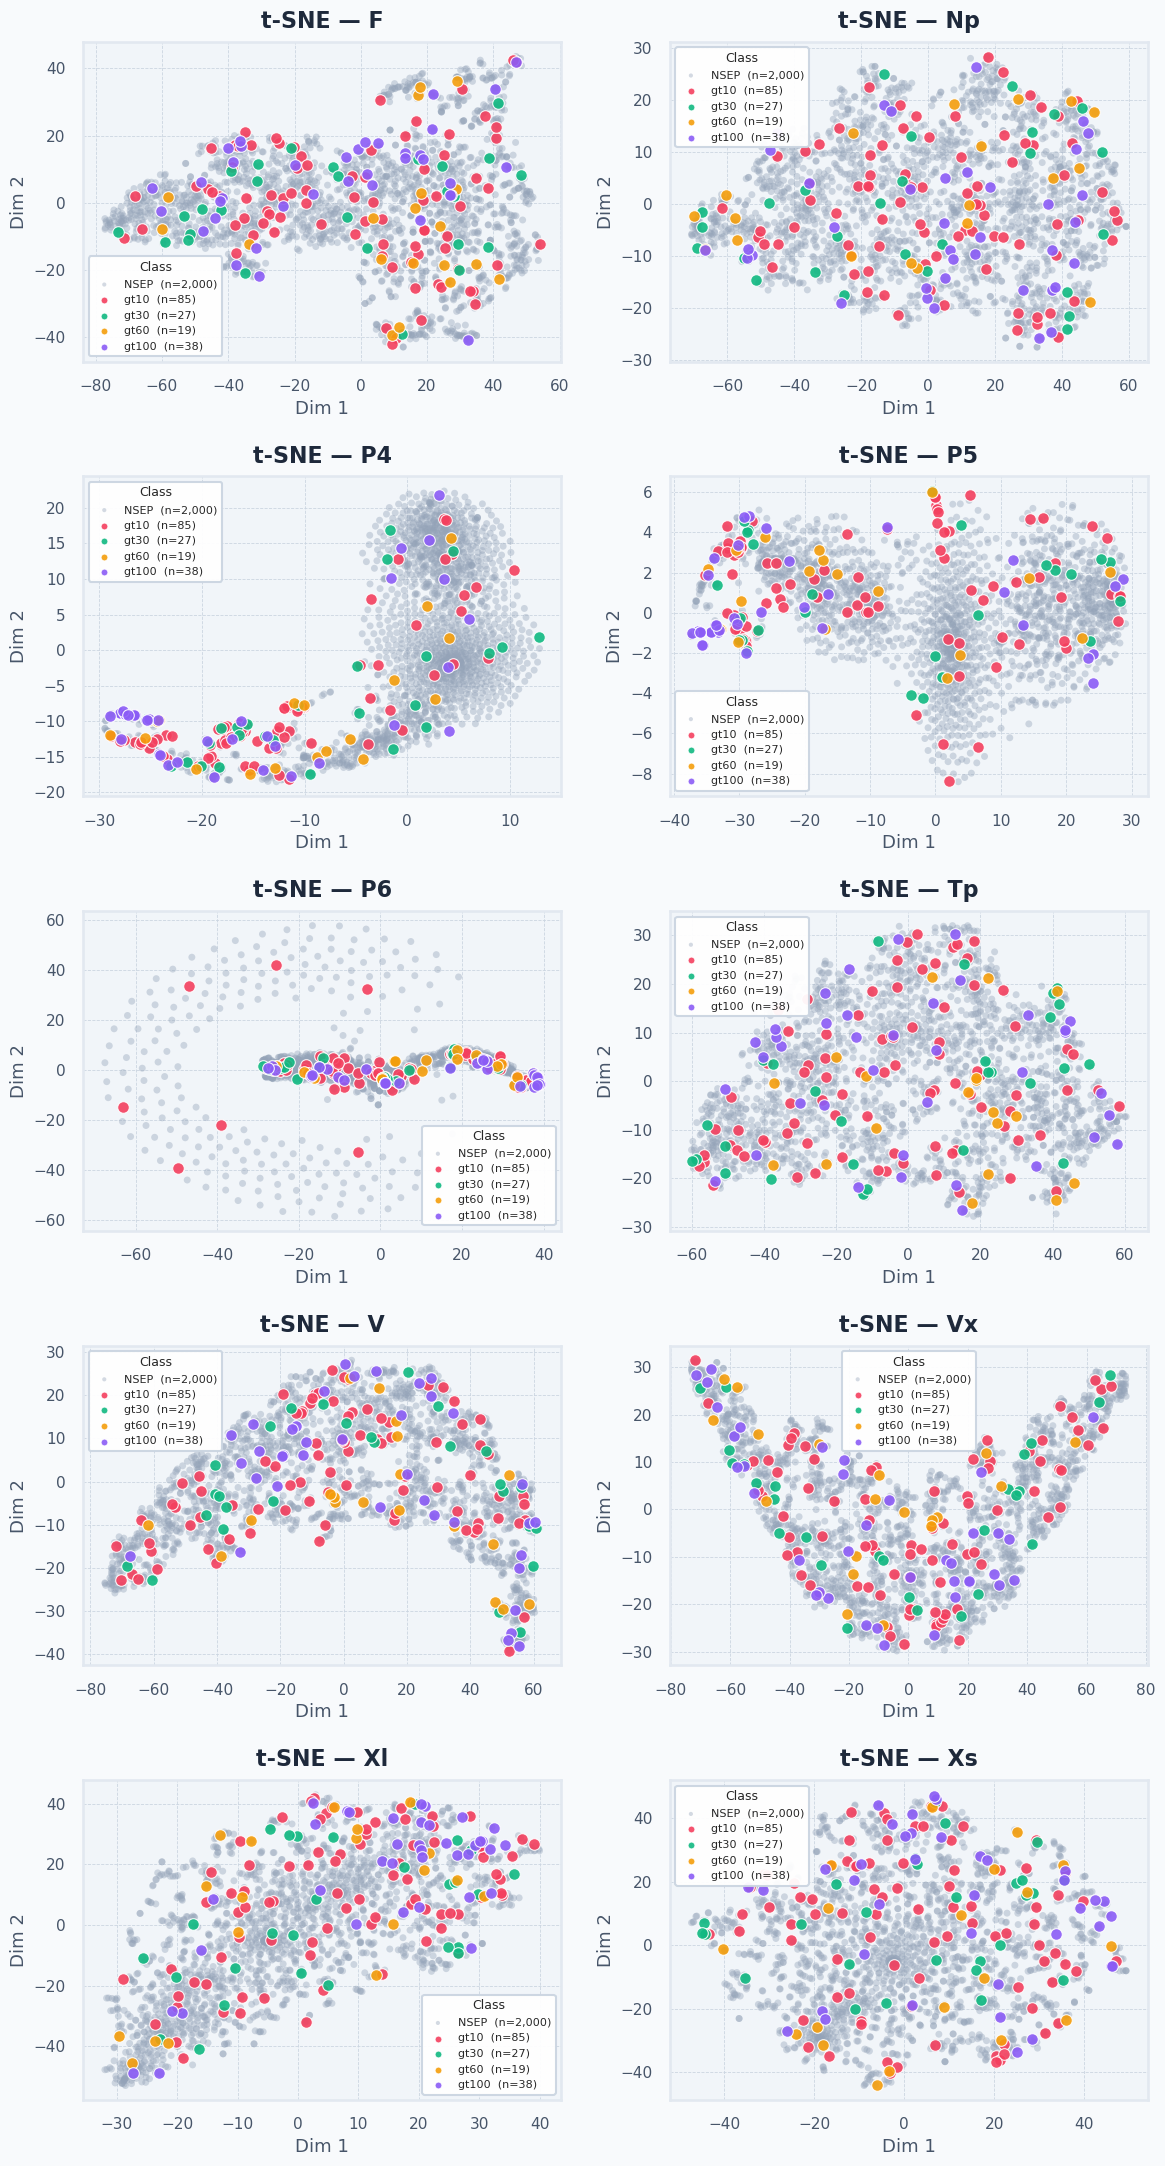

[DONE] F.csv
[DONE] Np.csv
[DONE] P4.csv
[DONE] P5.csv
[DONE] P6.csv
[DONE] Tp.csv
[DONE] V.csv
[DONE] Vx.csv
[DONE] Xl.csv
[DONE] Xs.csv
  Saved grid → ./tsne_plots/tsne_all_5x2.png

All done!


In [26]:
import warnings
warnings.filterwarnings('ignore')
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE

files = ['F.csv', 'Np.csv', 'P4.csv', 'P5.csv', 'P6.csv',
         'Tp.csv', 'V.csv', 'Vx.csv', 'Xl.csv', 'Xs.csv']

input_dir  = './output'
output_dir = './tsne_plots'
os.makedirs(output_dir, exist_ok=True)

label_names  = {0: 'NSEP', 1: 'gt10', 2: 'gt30', 3: 'gt60', 4: 'gt100'}
label_colors = {
    0: '#94A3B8',
    1: '#F43F5E',
    2: '#10B981',
    3: '#F59E0B',
    4: '#8B5CF6',
}

DOT_SMALL = 25
DOT_BIG   = 70
log       = []
rng       = np.random.default_rng(42)

# ── Collect all t-SNE results ─────────────────────────────────
tsne_results = []

for filename in files:
    filepath = f"{input_dir}/{filename}"
    if not os.path.exists(filepath):
        log.append(f"[SKIP] {filename} not found")
        tsne_results.append(None)
        continue

    devnull = open(os.devnull, 'w')
    old_out, old_err = sys.stdout, sys.stderr
    sys.stdout, sys.stderr = devnull, devnull
    try:
        df = pd.read_csv(filepath, header=None, low_memory=False)
        df = df.iloc[1:].reset_index(drop=True)
        df = df.apply(pd.to_numeric, errors='coerce')
        df = df.dropna()
        labels = df.iloc[:, 0].astype(int).values
        X      = df.iloc[:, 1:].values

        # ── Subsample NSEP to 500 ──
        nsep_idx = np.where(labels == 0)[0]
        sep_idx  = np.where(labels != 0)[0]
        if len(nsep_idx) > 2000:
            nsep_idx = rng.choice(nsep_idx, size=2000, replace=False)
        keep_idx = np.sort(np.concatenate([nsep_idx, sep_idx]))
        X        = X[keep_idx]
        labels   = labels[keep_idx]

        tsne = TSNE(n_components=2, random_state=42, perplexity=30,
                    max_iter=1000, verbose=0)
        X_2d = tsne.fit_transform(X)
        tsne_results.append((X_2d, labels, filename))
    except Exception as e:
        tsne_results.append(None)
        log.append(f"[ERROR] {filename}: {e}")
    finally:
        sys.stdout, sys.stderr = old_out, old_err
        devnull.close()

    if tsne_results[-1] is not None:
        print(f"  ✓ [{filename}] t-SNE done — {len(labels)} samples  "
              f"(NSEP={(labels==0).sum()}  SEP={(labels!=0).sum()})", flush=True)
    log.append(f"[DONE] {filename}")

# ── Plot individual figures ───────────────────────────────────
for item in tsne_results:
    if item is None:
        continue
    X_2d, labels, filename = item

    sns.set_theme(style='whitegrid', context='talk', font='DejaVu Sans')
    fig, ax = plt.subplots(figsize=(9, 7))
    fig.patch.set_facecolor('#F8FAFC')
    ax.set_facecolor('#F1F5F9')

    for label_id in sorted(label_names.keys()):
        mask = labels == label_id
        if mask.sum() == 0:
            continue
        is_nsep = label_id == 0
        ax.scatter(
            X_2d[mask, 0], X_2d[mask, 1],
            c=label_colors[label_id],
            s=DOT_SMALL if is_nsep else DOT_BIG,
            label=f"{label_names[label_id]}  (n={mask.sum():,})",
            alpha=0.4 if is_nsep else 0.9,
            edgecolors='none' if is_nsep else 'white',
            linewidths=0 if is_nsep else 0.8,
            zorder=1 if is_nsep else 2
        )

    ax.set_title(f't-SNE — {filename.replace(".csv", "")}',
                 fontsize=18, fontweight='bold', color='#1E293B', pad=16)
    ax.set_xlabel('t-SNE Dimension 1', fontsize=14, color='#475569', labelpad=10)
    ax.set_ylabel('t-SNE Dimension 2', fontsize=14, color='#475569', labelpad=10)
    ax.tick_params(colors='#475569', labelsize=12)
    for spine in ax.spines.values():
        spine.set_color('#E2E8F0')
    ax.yaxis.grid(True, color='#CBD5E1', linewidth=0.6, linestyle='--')
    ax.xaxis.grid(True, color='#CBD5E1', linewidth=0.6, linestyle='--')
    legend = ax.legend(
        title='Class', title_fontsize=10,
        fontsize=9, loc='best',
        framealpha=0.95, edgecolor='#CBD5E1',
        facecolor='white', markerscale=0.7,
    )
    legend.get_title().set_color('#1E293B')
    plt.tight_layout()
    plt.savefig(f'{output_dir}/{filename.replace(".csv", "_tsne.png")}',
                dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
    plt.close()

# ── Combined 5×2 grid figure ─────────────────────────────────
valid_results = [r for r in tsne_results if r is not None]

sns.set_theme(style='whitegrid', context='talk', font='DejaVu Sans')
fig, axes = plt.subplots(5, 2, figsize=(12, 22))
fig.patch.set_facecolor('#F8FAFC')
axes_flat = axes.flatten()

for idx, (X_2d, labels, filename) in enumerate(valid_results):
    ax = axes_flat[idx]
    ax.set_facecolor('#F1F5F9')

    for label_id in sorted(label_names.keys()):
        mask = labels == label_id
        if mask.sum() == 0:
            continue
        is_nsep = label_id == 0
        ax.scatter(
            X_2d[mask, 0], X_2d[mask, 1],
            c=label_colors[label_id],
            s=DOT_SMALL if is_nsep else DOT_BIG,
            label=f"{label_names[label_id]}  (n={mask.sum():,})",
            alpha=0.4 if is_nsep else 0.9,
            edgecolors='none' if is_nsep else 'white',
            linewidths=0 if is_nsep else 0.8,
            zorder=1 if is_nsep else 2
        )

    ax.set_title(f't-SNE — {filename.replace(".csv", "")}',
                 fontsize=16, fontweight='bold', color='#1E293B', pad=10)
    ax.set_xlabel('Dim 1', fontsize=13, color='#475569')
    ax.set_ylabel('Dim 2', fontsize=13, color='#475569')
    ax.tick_params(colors='#475569', labelsize=11)
    for spine in ax.spines.values():
        spine.set_color('#E2E8F0')
    ax.yaxis.grid(True, color='#CBD5E1', linewidth=0.6, linestyle='--')
    ax.xaxis.grid(True, color='#CBD5E1', linewidth=0.6, linestyle='--')
    ax.legend(title='Class', title_fontsize=9, fontsize=8,
              loc='best', framealpha=0.95,
              edgecolor='#CBD5E1', facecolor='white',
              markerscale=0.6)

for idx in range(len(valid_results), len(axes_flat)):
    axes_flat[idx].set_visible(False)


plt.tight_layout()
plt.savefig(f'{output_dir}/tsne_all_5x2.png', dpi=150,
            bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()
plt.close()

log.append(f"  Saved grid → {output_dir}/tsne_all_5x2.png")
log.append("\nAll done!")
print('\n'.join(log))

## 4. Combine Features into MVTS

In [27]:
import pandas as pd
import numpy as np
import pickle
import os

files = ['F.csv', 'Np.csv', 'P4.csv', 'P5.csv', 'P6.csv',
         'Tp.csv', 'V.csv', 'Vx.csv', 'Xl.csv', 'Xs.csv']

input_dir  = './output'
output_dir = './mvts'
os.makedirs(output_dir, exist_ok=True)

all_X = []
all_y = []

for filename in files:
    filepath = f"{input_dir}/{filename}"
    if not os.path.exists(filepath):
        print(f"[SKIP] {filename} not found")
        continue

    print(f"Loading: {filename}")

    df = pd.read_csv(filepath, header=None, low_memory=False)
    df = df.apply(pd.to_numeric, errors='coerce')
    df = df.dropna()

    labels = df.iloc[:, 0].astype(int).values   # (num_samples,)
    ts     = df.iloc[:, 1:].values               # (num_samples, 288)

    all_X.append(ts)
    all_y.append(labels)

    print(f"  Samples: {len(labels)}  |  Timesteps: {ts.shape[1]}")

# Stack all files
# Each file = one feature → shape becomes (num_samples, num_timesteps, num_features)
X = np.stack(all_X, axis=-1)   # (num_samples, 288, 10)
y = all_y[0]                    # labels are the same across all files

print(f"\nFinal dataset shape : {X.shape}  →  (samples, timesteps, features)")
print(f"Labels shape        : {y.shape}")
print(f"Label distribution  : {dict(zip(*np.unique(y, return_counts=True)))}")

# Save X as pickle
pickle_path = os.path.join(output_dir, 'X.pkl')
with open(pickle_path, 'wb') as f:
    pickle.dump(X, f)
print(f"\nSaved X → {pickle_path}")

# Save y as 1D csv
labels_path = os.path.join(output_dir, 'y.csv')
pd.Series(y).to_csv(labels_path, index=False, header=False)
print(f"Saved y → {labels_path}")

print("\nAll done!")

Loading: F.csv
  Samples: 17794  |  Timesteps: 288
Loading: Np.csv
  Samples: 17794  |  Timesteps: 288
Loading: P4.csv
  Samples: 17794  |  Timesteps: 288
Loading: P5.csv
  Samples: 17794  |  Timesteps: 288
Loading: P6.csv
  Samples: 17794  |  Timesteps: 288
Loading: Tp.csv
  Samples: 17794  |  Timesteps: 288
Loading: V.csv
  Samples: 17794  |  Timesteps: 288
Loading: Vx.csv
  Samples: 17794  |  Timesteps: 288
Loading: Xl.csv
  Samples: 17794  |  Timesteps: 288
Loading: Xs.csv
  Samples: 17794  |  Timesteps: 288

Final dataset shape : (17794, 288, 10)  →  (samples, timesteps, features)
Labels shape        : (17794,)
Label distribution  : {np.int64(0): np.int64(17625), np.int64(1): np.int64(85), np.int64(2): np.int64(27), np.int64(3): np.int64(19), np.int64(4): np.int64(38)}

Saved X → ./mvts/X.pkl
Saved y → ./mvts/y.csv

All done!


## 5. t-SNE — MVTS Classes

Running PCA …


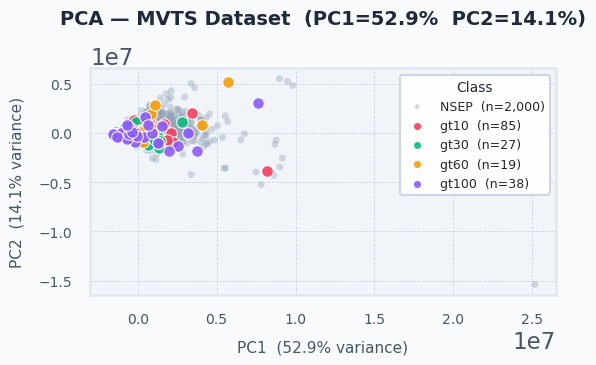

✅  PCA done
Running t-SNE …


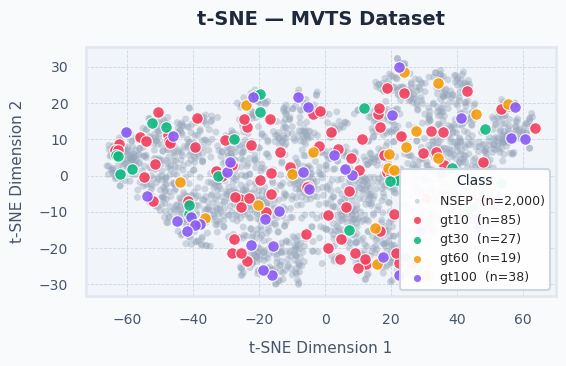

✅  t-SNE done


In [28]:
import warnings
warnings.filterwarnings('ignore')
import os
import contextlib
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

input_dir  = './mvts'
output_dir = './plots'
os.makedirs(output_dir, exist_ok=True)

# ── Load data ─────────────────────────────────────────────────
with open(f'{input_dir}/X.pkl', 'rb') as f:
    X = pickle.load(f)
y = pd.read_csv(f'{input_dir}/y.csv', header=None).values.flatten().astype(int)

# ── Subsample NSEP to 2000 ────────────────────────────────────
rng      = np.random.default_rng(42)
nsep_idx = np.where(y == 0)[0]
sep_idx  = np.where(y != 0)[0]
if len(nsep_idx) > 2000:
    nsep_idx = rng.choice(nsep_idx, size=2000, replace=False)
keep_idx = np.sort(np.concatenate([nsep_idx, sep_idx]))
X        = X[keep_idx]
y        = y[keep_idx]

X_flat = X.reshape(X.shape[0], -1)

label_names  = {0: 'NSEP', 1: 'gt10', 2: 'gt30', 3: 'gt60', 4: 'gt100'}
label_colors = {
    0: '#94A3B8',
    1: '#F43F5E',
    2: '#10B981',
    3: '#F59E0B',
    4: '#8B5CF6',
}

DOT_SMALL = 25
DOT_BIG   = 70

def plot_embedding(X_2d, y, title, filename, xlabel, ylabel):
    sns.set_theme(style='whitegrid', context='talk', font='DejaVu Sans')
    fig, ax = plt.subplots(figsize=(6, 4))
    fig.patch.set_facecolor('#F8FAFC')
    ax.set_facecolor('#F1F5F9')

    for label_id in sorted(label_names.keys()):
        mask = y == label_id
        if mask.sum() == 0:
            continue
        is_nsep = label_id == 0
        ax.scatter(
            X_2d[mask, 0], X_2d[mask, 1],
            c=label_colors[label_id],
            s=DOT_SMALL if is_nsep else DOT_BIG,
            label=f"{label_names[label_id]}  (n={mask.sum():,})",
            alpha=0.4 if is_nsep else 0.9,
            edgecolors='none' if is_nsep else 'white',
            linewidths=0 if is_nsep else 0.8,
            zorder=1 if is_nsep else 2
        )

    ax.set_title(title, fontsize=14, fontweight='bold', color='#1E293B', pad=16)
    ax.set_xlabel(xlabel, fontsize=11, color='#475569', labelpad=10)
    ax.set_ylabel(ylabel, fontsize=11, color='#475569', labelpad=10)
    ax.tick_params(colors='#475569', labelsize=10)
    for spine in ax.spines.values():
        spine.set_color('#E2E8F0')
    ax.yaxis.grid(True, color='#CBD5E1', linewidth=0.6, linestyle='--')
    ax.xaxis.grid(True, color='#CBD5E1', linewidth=0.6, linestyle='--')
    legend = ax.legend(
        title='Class', title_fontsize=10,
        fontsize=9, loc='best',
        framealpha=0.95, edgecolor='#CBD5E1',
        facecolor='white', markerscale=0.7,
    )
    legend.get_title().set_color('#1E293B')
    plt.tight_layout()
    plt.savefig(f'{output_dir}/{filename}', dpi=150,
                bbox_inches='tight', facecolor=fig.get_facecolor())
    plt.show()
    plt.close()

def silence(func, *args, **kwargs):
    with open(os.devnull, 'w') as devnull:
        with contextlib.redirect_stdout(devnull), contextlib.redirect_stderr(devnull):
            return func(*args, **kwargs)

# ── PCA ───────────────────────────────────────────────────────
print("Running PCA …", flush=True)
pca   = PCA(n_components=2, random_state=42)
X_pca = silence(pca.fit_transform, X_flat)
var   = pca.explained_variance_ratio_ * 100
plot_embedding(
    X_pca, y,
    title=f'PCA — MVTS Dataset  (PC1={var[0]:.1f}%  PC2={var[1]:.1f}%)',
    filename='pca.png',
    xlabel=f'PC1  ({var[0]:.1f}% variance)',
    ylabel=f'PC2  ({var[1]:.1f}% variance)'
)
print("✅  PCA done", flush=True)

# ── t-SNE ─────────────────────────────────────────────────────
print("Running t-SNE …", flush=True)
pca50   = PCA(n_components=50, random_state=42)
X_pca50 = silence(pca50.fit_transform, X_flat)
tsne    = TSNE(n_components=2, random_state=42, perplexity=30,
               max_iter=1000, verbose=0)
X_tsne  = silence(tsne.fit_transform, X_pca50)
plot_embedding(
    X_tsne, y,
    title='t-SNE — MVTS Dataset',
    filename='tsne.png',
    xlabel='t-SNE Dimension 1',
    ylabel='t-SNE Dimension 2'
)
print("✅  t-SNE done", flush=True)

## 6. Class Distribution

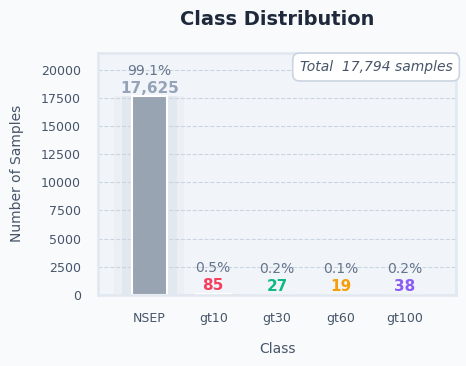

In [29]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import os

input_dir  = './mvts'
output_dir = './plots'
os.makedirs(output_dir, exist_ok=True)

y = pd.read_csv(f'{input_dir}/y.csv', header=None).values.flatten().astype(int)

label_names  = {0: 'NSEP', 1: 'gt10', 2: 'gt30', 3: 'gt60', 4: 'gt100'}
label_colors = {
    0: '#94A3B8',
    1: '#F43F5E',
    2: '#10B981',
    3: '#F59E0B',
    4: '#8B5CF6',
}

unique, counts = np.unique(y, return_counts=True)
total = counts.sum()

df_plot = pd.DataFrame({
    'Class'  : [label_names[i] for i in unique],
    'Samples': counts,
    'Color'  : [label_colors[i] for i in unique]
})

sns.set_theme(style='whitegrid', context='talk', font='DejaVu Sans')
fig, ax = plt.subplots(figsize=(5, 4))
fig.patch.set_facecolor('#F8FAFC')
ax.set_facecolor('#F1F5F9')

sns.barplot(
    data=df_plot,
    x='Class', y='Samples',
    palette=df_plot['Color'].tolist(),
    edgecolor='white', linewidth=1.5,
    ax=ax, width=0.55
)

for bar, label_id in zip(ax.patches, unique):
    cx = bar.get_x() + bar.get_width() / 2
    for alpha, extra_w in [(0.10, 0.30), (0.05, 0.55)]:
        ax.bar(cx, bar.get_height(),
               width=bar.get_width() + extra_w,
               color=label_colors[label_id],
               alpha=alpha, zorder=0, edgecolor='none')

for bar, count, label_id in zip(ax.patches, counts, unique):
    pct = 100 * count / total
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + total * 0.004,
        f'{count:,}',
        ha='center', va='bottom',
        fontsize=11, fontweight='bold',
        color=label_colors[label_id],
    )
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + total * 0.004 + counts.max() * 0.09,
        f'{pct:.1f}%',
        ha='center', va='bottom',
        fontsize=10, color='#64748B',
    )

ax.yaxis.grid(True, color='#CBD5E1', linewidth=0.8, linestyle='--')
ax.set_axisbelow(True)
for spine in ax.spines.values():
    spine.set_color('#E2E8F0')

ax.set_title('Class Distribution', fontsize=14, fontweight='bold',
             color='#1E293B', pad=20)
ax.set_xlabel('Class', fontsize=10, color='#475569', labelpad=12)
ax.set_ylabel('Number of Samples', fontsize=10, color='#475569', labelpad=12)
ax.tick_params(colors='#475569', labelsize=9)
ax.set_ylim(0, counts.max() * 1.22)

ax.text(0.99, 0.97, f'Total  {total:,} samples',
        transform=ax.transAxes, ha='right', va='top',
        fontsize=10, color='#475569', fontstyle='italic',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white',
                  edgecolor='#CBD5E1', linewidth=1.2))

plt.tight_layout()
plt.savefig(f'{output_dir}/class_distribution.png', dpi=150,
            bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()   # ← display inline
plt.close()

## 7. Multiclass to Binary Labels

In [30]:
import pandas as pd
import numpy as np
import pickle
import os
from collections import Counter

variants = [
    ('./mvts', './mvts_binary'),
]

for input_dir, output_dir in variants:
    print(f"\n{'='*55}")
    print(f"Input  : {input_dir}")
    print(f"Output : {output_dir}")
    print('='*55)
    os.makedirs(output_dir, exist_ok=True)
    with open(f'{input_dir}/X.pkl', 'rb') as f:
        X = pickle.load(f)
    y = pd.read_csv(f'{input_dir}/y.csv', header=None).values.flatten().astype(int)
    print(f"Original Distribution : {Counter(y)}")
    y_binary = np.where(y > 0, 1, 0)
    print(f"Binary Distribution   : {Counter(y_binary)}")
    with open(f'{output_dir}/X.pkl', 'wb') as f:
        pickle.dump(X, f)
    pd.Series(y_binary).to_csv(f'{output_dir}/y.csv', index=False, header=False)
    print(f"Saved X → {output_dir}/X.pkl")
    print(f"Saved y → {output_dir }/y.csv")

print("\nAll done!")


Input  : ./mvts
Output : ./mvts_binary
Original Distribution : Counter({np.int64(0): 17625, np.int64(1): 85, np.int64(4): 38, np.int64(2): 27, np.int64(3): 19})
Binary Distribution   : Counter({np.int64(0): 17625, np.int64(1): 169})
Saved X → ./mvts_binary/X.pkl
Saved y → ./mvts_binary/y.csv

All done!


## 8. Separate SEP and Non-SEP

In [31]:
import numpy as np
import pickle
import pandas as pd
import os
from collections import Counter

variants = [
    './mvts_binary',
]

for input_dir in variants:
    print(f"\n{'='*55}")
    print(f"Input : {input_dir}")
    print('='*55)
    with open(f'{input_dir}/X.pkl', 'rb') as f:
        X = pickle.load(f)
    y = pd.read_csv(f'{input_dir}/y.csv', header=None).values.flatten().astype(int)
    print(f"Full Dataset Distribution : {Counter(y)}")
    nsep_idx = np.where(y == 0)[0]
    sep_idx  = np.where(y == 1)[0]
    X_nsep = X[nsep_idx];  y_nsep = y[nsep_idx]
    X_sep  = X[sep_idx];   y_sep  = y[sep_idx]
    print(f"NSEP (Class 0) Samples    : {X_nsep.shape[0]:,}")
    print(f"SEP  (Class 1) Samples    : {X_sep.shape[0]:,}")
    with open(f'{input_dir}/X_nsep.pkl', 'wb') as f:
        pickle.dump(X_nsep, f)
    with open(f'{input_dir}/X_sep.pkl', 'wb') as f:
        pickle.dump(X_sep, f)
    pd.Series(y_nsep).to_csv(f'{input_dir}/y_nsep.csv', index=False, header=False)
    pd.Series(y_sep).to_csv(f'{input_dir}/y_sep.csv',   index=False, header=False)
    print(f"Saved X_nsep, X_sep, y_nsep, y_sep → {input_dir}/")

print("\nAll done!")


Input : ./mvts_binary
Full Dataset Distribution : Counter({np.int64(0): 17625, np.int64(1): 169})
NSEP (Class 0) Samples    : 17,625
SEP  (Class 1) Samples    : 169
Saved X_nsep, X_sep, y_nsep, y_sep → ./mvts_binary/

All done!


## 9. Train / Validation / Test Split (70-10-20)

In [32]:
import numpy as np
import pandas as pd
import pickle
import os
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle

variants = [
    ('./mvts_binary',                './final_split_data_noNorm'),
]

def save_bundle(X_data, y_data, filepath):
    with open(filepath, 'wb') as f:
        pickle.dump({'X': X_data, 'y': y_data}, f)
    print(f"Saved : {filepath}")

for input_dir, output_dir in variants:
    print(f"\n{'='*55}")
    print(f"Input  : {input_dir}")
    print(f"Output : {output_dir}")
    print('='*55)
    os.makedirs(output_dir, exist_ok=True)
    with open(f'{input_dir}/X_nsep.pkl', 'rb') as f:
        X_nsep = pickle.load(f)
    with open(f'{input_dir}/X_sep.pkl', 'rb') as f:
        X_sep = pickle.load(f)
    y_nsep = pd.read_csv(f'{input_dir}/y_nsep.csv', header=None).values.flatten().astype(int)
    y_sep  = pd.read_csv(f'{input_dir}/y_sep.csv',  header=None).values.flatten().astype(int)
    print(f"NSEP samples : {X_nsep.shape[0]:,}")
    print(f"SEP  samples : {X_sep.shape[0]:,}")
    # ── Step 1: Split NSEP 70-10-20 ──────────────────────────────────────────
    X_nsep_tv, X_nsep_test, y_nsep_tv, y_nsep_test = train_test_split(
        X_nsep, y_nsep, test_size=0.20, random_state=42, shuffle=False)
    X_nsep_train, X_nsep_val, y_nsep_train, y_nsep_val = train_test_split(
        X_nsep_tv, y_nsep_tv, test_size=0.125, random_state=42, shuffle=False)
    # ── Step 2: Split SEP 70-10-20 ───────────────────────────────────────────
    X_sep_tv, X_sep_test, y_sep_tv, y_sep_test = train_test_split(
        X_sep, y_sep, test_size=0.20, random_state=42, shuffle=False)
    X_sep_train, X_sep_val, y_sep_train, y_sep_val = train_test_split(
        X_sep_tv, y_sep_tv, test_size=0.125, random_state=42, shuffle=False)
    # ── Step 3: Combine ───────────────────────────────────────────────────────
    X_train = np.concatenate([X_nsep_train, X_sep_train], axis=0)
    y_train = np.concatenate([y_nsep_train, y_sep_train], axis=0)
    X_val   = np.concatenate([X_nsep_val,   X_sep_val],   axis=0)
    y_val   = np.concatenate([y_nsep_val,   y_sep_val],   axis=0)
    X_test  = np.concatenate([X_nsep_test,  X_sep_test],  axis=0)
    y_test  = np.concatenate([y_nsep_test,  y_sep_test],  axis=0)
    # ── Step 4: Shuffle ───────────────────────────────────────────────────────
    X_train, y_train = shuffle(X_train, y_train, random_state=42)
    X_val,   y_val   = shuffle(X_val,   y_val,   random_state=42)
    X_test,  y_test  = shuffle(X_test,  y_test,  random_state=42)
    print(f"\nTrain : {X_train.shape[0]:,} samples  |  {Counter(y_train)}")
    print(f"Val   : {X_val.shape[0]:,}   samples  |  {Counter(y_val)}")
    print(f"Test  : {X_test.shape[0]:,}  samples  |  {Counter(y_test)}")
    # ── Step 5: Save ─────────────────────────────────────────────────────────
    save_bundle(X_train, y_train, os.path.join(output_dir, 'train_set.pkl'))
    save_bundle(X_val,   y_val,   os.path.join(output_dir, 'val_set.pkl'))
    save_bundle(X_test,  y_test,  os.path.join(output_dir, 'test_set.pkl'))
    del X_nsep, X_sep, X_train, X_val, X_test

print("\nAll done!")


Input  : ./mvts_binary
Output : ./final_split_data_noNorm
NSEP samples : 17,625
SEP  samples : 169

Train : 12,455 samples  |  Counter({np.int64(0): 12337, np.int64(1): 118})
Val   : 1,780   samples  |  Counter({np.int64(0): 1763, np.int64(1): 17})
Test  : 3,559  samples  |  Counter({np.int64(0): 3525, np.int64(1): 34})
Saved : ./final_split_data_noNorm/train_set.pkl
Saved : ./final_split_data_noNorm/val_set.pkl
Saved : ./final_split_data_noNorm/test_set.pkl

All done!


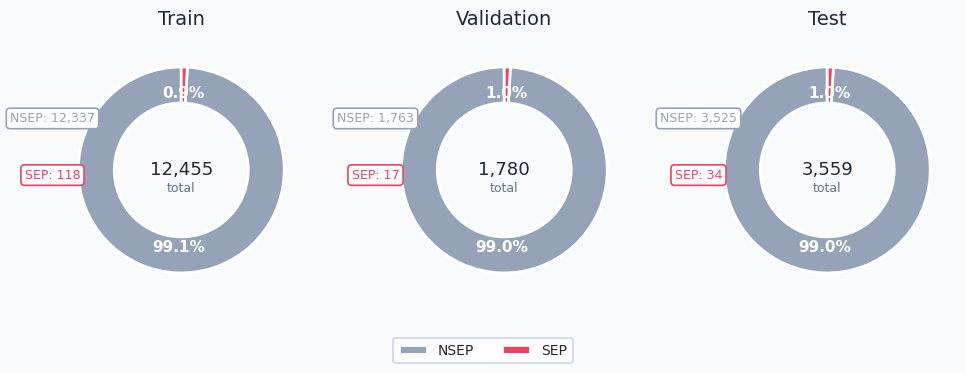

✅  Saved → ./plots/split_distribution_noNorm.png


In [33]:
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import os

input_dir  = './final_split_data_noNorm'
output_dir = './plots'
os.makedirs(output_dir, exist_ok=True)

# ── Load splits ──
def load_bundle(path):
    with open(path, 'rb') as f:
        d = pickle.load(f)
    return d['y']

y_train = load_bundle(f'{input_dir}/train_set.pkl')
y_val   = load_bundle(f'{input_dir}/val_set.pkl')
y_test  = load_bundle(f'{input_dir}/test_set.pkl')

splits = {
    'Train': y_train,
    'Validation'  : y_val,
    'Test' : y_test,
}

colors = ['#94A3B8', '#F43F5E']  # NSEP, SEP

# ── Plot ──
fig, axes = plt.subplots(1, 3, figsize=(10, 5))
fig.patch.set_facecolor('#F8FAFC')

for ax, (split_name, y) in zip(axes, splits.items()):
    unique, counts = np.unique(y, return_counts=True)
    labels         = ['NSEP' if u == 0 else 'SEP' for u in unique]
    total          = counts.sum()

    wedges, texts, autotexts = ax.pie(
        counts,
        labels      = None,
        colors      = colors,
        autopct     = '%1.1f%%',
        startangle  = 90,
        pctdistance = 0.75,
        wedgeprops  = dict(width=0.35, edgecolor='white', linewidth=2),
    )

    for at in autotexts:
        at.set_fontsize(11)
        at.set_fontweight('bold')
        at.set_color('white')

    # center text
    ax.text(0, 0, f'{total:,}', ha='center', va='center',
            fontsize=13, color='#1E293B')
    ax.text(0, -0.18, 'total', ha='center', va='center',
            fontsize=9, color='#64748B')

    ax.set_title(split_name, fontsize=14,
                 color='#1E293B', pad=12)

    # count annotations
    for i, (count, label) in enumerate(zip(counts, labels)):
        ax.text(0, 0.7 - i * 0.22, f'{label}: {count:,}',
                ha='center', va='center',
                fontsize=9, color=colors[i],
                transform=ax.transAxes,
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                          edgecolor=colors[i], linewidth=1.2))

# legend
fig.legend(['NSEP', 'SEP'], loc='lower center', ncol=2,
           fontsize=10, frameon=True,
           facecolor='white', edgecolor='#CBD5E1',
           bbox_to_anchor=(0.5, 0.1))

plt.tight_layout()
plt.savefig(f'{output_dir}/split_distribution_noNorm.png', dpi=150,
            bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()
plt.close()
print("✅  Saved → ./plots/split_distribution_noNorm.png")

## 10. Hybrid Normalization

In [34]:
import numpy as np
import pickle
import os

# ---------------------------------------------------------
# Input/output directories
# ---------------------------------------------------------
input_dir = './final_split_data_noNorm'
output_dir = './final_split_data_HybridNorm'
os.makedirs(output_dir, exist_ok=True)

feature_names = ['F', 'Np', 'P4', 'P5', 'P6', 'Tp', 'V', 'Vx', 'Xl', 'Xs']

# log10 -> z-score (heavy-tailed, multi-decade quantities)
log_zscore_features = ['F', 'Np', 'P4', 'P5', 'P6', 'Tp', 'Xl', 'Xs']

# plain z-score (roughly unimodal, can be signed)
zscore_features = ['V', 'Vx']


# ---------------------------------------------------------
# Load saved bundles
# ---------------------------------------------------------
def load_bundle(path):
    with open(path, 'rb') as f:
        data = pickle.load(f)
    return data['X'], data['y']


X_train, y_train = load_bundle(os.path.join(input_dir, 'train_set.pkl'))
X_val, y_val     = load_bundle(os.path.join(input_dir, 'val_set.pkl'))
X_test, y_test   = load_bundle(os.path.join(input_dir, 'test_set.pkl'))

print("Before normalization:")
print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)


# ---------------------------------------------------------
# Fit normalizer using training set only
# ---------------------------------------------------------
def fit_hybrid_normalizer(X_train, feature_names):
    """
    X_train shape: (N, T, F)
    Fits one normalization rule per feature using training data only.

    log_zscore : y = (log10(max(x + eps, floor)) - mean) / std
    zscore     : y = (x - mean) / std
    """

    params = {}

    for j, name in enumerate(feature_names):
        values = X_train[:, :, j].reshape(-1).astype(float)

        if name in log_zscore_features:
            # Small positive offset so log10 stays finite near zero.
            positive_values = values[values > 0]

            if len(positive_values) == 0:
                eps = 1e-8
            else:
                eps = np.nanpercentile(positive_values, 0.1)

                if not np.isfinite(eps) or eps <= 0:
                    eps = 1e-8

            # If the feature still dips to/below zero after adding eps, shift
            # it up using its own spread, so the training minimum lands on a
            # sensible small value instead of on 1e-8 (which would become
            # log10 = -8, an artificial outlier that skews the fitted
            # mean/std).
            shifted = False
            min_value = np.nanmin(values)

            if min_value + eps <= 0:
                centred = values - min_value
                pos_centred = centred[centred > 0]

                if len(pos_centred) == 0:
                    delta = 1e-8
                else:
                    delta = np.nanpercentile(pos_centred, 0.1)
                    if not np.isfinite(delta) or delta <= 0:
                        delta = 1e-8

                eps = abs(min_value) + delta
                shifted = True

            # Floor used at transform time: the smallest positive value seen in
            # training. Val/test samples below the training range get clipped
            # here instead of producing log10(<=0) -> NaN / -inf.
            floor = np.nanmin(values + eps)

            if not np.isfinite(floor) or floor <= 0:
                floor = 1e-12

            transformed = np.log10(np.maximum(values + eps, floor))

            mean = np.nanmean(transformed)
            std = np.nanstd(transformed)

            if std == 0 or not np.isfinite(std):
                std = 1.0

            params[name] = {
                'method': 'log_zscore',
                'eps': eps,
                'floor': floor,
                'shifted': shifted,
                'mean': mean,
                'std': std
            }

        elif name in zscore_features:
            mean = np.nanmean(values)
            std = np.nanstd(values)

            if std == 0 or not np.isfinite(std):
                std = 1.0

            params[name] = {
                'method': 'zscore',
                'mean': mean,
                'std': std
            }

        else:
            raise ValueError(f"No normalization method defined for feature: {name}")

    return params


# ---------------------------------------------------------
# Apply fitted normalizer
# ---------------------------------------------------------
def apply_hybrid_normalizer(X, feature_names, params, split_name=''):
    """
    Applies training-set normalization parameters to any split.
    Reports how many values had to be clipped at the log floor.
    """

    X_norm = X.copy().astype(np.float32)
    clip_report = {}

    for j, name in enumerate(feature_names):
        p = params[name]

        if p['method'] == 'log_zscore':
            shifted_vals = X_norm[:, :, j].astype(np.float64) + p['eps']

            n_clipped = int(np.sum(shifted_vals < p['floor']))
            if n_clipped > 0:
                clip_report[name] = n_clipped

            X_log = np.log10(np.maximum(shifted_vals, p['floor']))
            X_norm[:, :, j] = ((X_log - p['mean']) / p['std']).astype(np.float32)

        elif p['method'] == 'zscore':
            X_norm[:, :, j] = (X_norm[:, :, j] - p['mean']) / p['std']

    if clip_report:
        total = X.shape[0] * X.shape[1]
        print(f"  [{split_name}] values clipped at log floor (below training range):")
        for name, n in clip_report.items():
            print(f"    {name}: {n} / {total} ({100.0 * n / total:.4f}%)")

    return X_norm


# ---------------------------------------------------------
# Fit only on training data
# ---------------------------------------------------------
norm_params = fit_hybrid_normalizer(X_train, feature_names)

# Report which features needed a shift to become strictly positive
shifted_features = [n for n in feature_names
                    if norm_params[n]['method'] == 'log_zscore' and norm_params[n]['shifted']]
if shifted_features:
    print("\nFeatures shifted to positive before log10:", shifted_features)
else:
    print("\nNo feature required a positive shift before log10.")

# ---------------------------------------------------------
# Transform all splits using same parameters
# ---------------------------------------------------------
print("\nApplying normalization:")
X_train_norm = apply_hybrid_normalizer(X_train, feature_names, norm_params, 'train')
X_val_norm   = apply_hybrid_normalizer(X_val, feature_names, norm_params, 'val')
X_test_norm  = apply_hybrid_normalizer(X_test, feature_names, norm_params, 'test')


# ---------------------------------------------------------
# Safety checks
# ---------------------------------------------------------
for split_name, X_split in [
    ('train', X_train_norm),
    ('val', X_val_norm),
    ('test', X_test_norm)
]:
    if np.isnan(X_split).any():
        raise ValueError(f"{split_name} contains NaN after normalization.")

    if np.isinf(X_split).any():
        raise ValueError(f"{split_name} contains Inf after normalization.")

print("\nAfter normalization:")
print("Train:", X_train_norm.shape)
print("Val  :", X_val_norm.shape)
print("Test :", X_test_norm.shape)


# ---------------------------------------------------------
# Print normalization parameters
# ---------------------------------------------------------
print("\nNormalization parameters:")
for name in feature_names:
    print(f"\n{name}:")
    for k, v in norm_params[name].items():
        print(f"  {k}: {v}")


# ---------------------------------------------------------
# Save normalized bundles
# ---------------------------------------------------------
def save_bundle(X, y, path):
    with open(path, 'wb') as f:
        pickle.dump({'X': X, 'y': y}, f)
    print(f"Saved: {path}")


save_bundle(X_train_norm, y_train, os.path.join(output_dir, 'train_set.pkl'))
save_bundle(X_val_norm,   y_val,   os.path.join(output_dir, 'val_set.pkl'))
save_bundle(X_test_norm,  y_test,  os.path.join(output_dir, 'test_set.pkl'))

# Save normalization parameters too
with open(os.path.join(output_dir, 'normalization_params.pkl'), 'wb') as f:
    pickle.dump(norm_params, f)

print(f"\nSaved normalization parameters -> {output_dir}/normalization_params.pkl")
print("\nAll done!")


Before normalization:
Train: (12455, 288, 10) (12455,)
Val  : (1780, 288, 10) (1780,)
Test : (3559, 288, 10) (3559,)

No feature required a positive shift before log10.

Applying normalization:
  [train] values clipped at log floor (below training range):
    F: 3 / 3587040 (0.0001%)
    P6: 1 / 3587040 (0.0000%)
  [val] values clipped at log floor (below training range):
    Xl: 1740 / 512640 (0.3394%)
    Xs: 1111 / 512640 (0.2167%)
  [test] values clipped at log floor (below training range):
    Xl: 1206 / 1024992 (0.1177%)
    Xs: 16 / 1024992 (0.0016%)

After normalization:
Train: (12455, 288, 10)
Val  : (1780, 288, 10)
Test : (3559, 288, 10)

Normalization parameters:

F:
  method: log_zscore
  eps: 1.49000000954
  floor: 1.7600000202689998
  shifted: False
  mean: 1.0481208176105241
  std: 0.6496822739104459

Np:
  method: log_zscore
  eps: 0.230000004172
  floor: 0.2600000035014
  shifted: False
  mean: 0.6898441445357585
  std: 0.29806075704908136

P4:
  method: log_zscore
  e

In [35]:
import pickle
import numpy as np

with open('./final_split_data_HybridNorm/train_set.pkl', 'rb') as f:
    train = pickle.load(f)

X_train = train['X']

feature_names = ['F', 'Np', 'P4', 'P5', 'P6', 'Tp', 'V', 'Vx', 'Xl', 'Xs']

print(f"{'Feature':<6} {'Min':>10} {'Max':>10} {'Mean':>10} {'Std':>10} {'Median':>10}")
print("-" * 66)

for j, name in enumerate(feature_names):
    vals = X_train[:, :, j].reshape(-1)

    print(
        f"{name:<6} "
        f"{np.min(vals):>10.3f} "
        f"{np.max(vals):>10.3f} "
        f"{np.mean(vals):>10.3f} "
        f"{np.std(vals):>10.3f} "
        f"{np.median(vals):>10.3f}"
    )

Feature        Min        Max       Mean        Std     Median
------------------------------------------------------------------
F          -1.235      4.544     -0.000      1.000     -0.226
Np         -4.277      3.875      0.000      1.000     -0.053
P4         -1.786      8.476      0.000      1.000     -0.242
P5         -2.150     12.718      0.000      1.000     -0.145
P6         -2.333     18.192      0.000      1.000     -0.107
Tp         -3.182      5.459     -0.000      1.000      0.034
V          -2.062      6.519     -0.000      1.000     -0.212
Vx         -6.514      2.090      0.000      1.000      0.212
Xl         -3.556      9.363      0.000      1.000     -0.092
Xs         -1.623      7.127     -0.000      1.000     -0.119


## 11. GRU Training — Hybrid-Normalized Data

Trains a GRU on the Hybrid-normalized data using the fixed best
hyperparameters (`units=64, layers=1, dropout=0.1, lr=0.001, batch_size=64`)
and reports metrics on the test set. Results are printed only — not saved to
a file.

In [36]:
import torch
import torch.nn as nn
import numpy as np
import time
from sklearn.metrics import confusion_matrix, brier_score_loss
import warnings
warnings.filterwarnings('ignore')

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")


def compute_metrics(y_true, y_pred):
    cm             = confusion_matrix(y_true, y_pred)
    TN, FP, FN, TP = cm.ravel()

    # Probability of Detection (PoD), MEMPSEP Section 9.2 item 1.
    # Identical formula to recall -- kept as a separate named field so
    # printed output matches the paper's terminology.
    pod       = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    recall    = pod
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    f1        = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    accuracy  = (TP + TN) / (TP + TN + FP + FN)

    tss  = recall - FP / (FP + TN) if (FP + TN) > 0 else 0.0

    # HSS1 (Barnes & Leka 2008): (TP + TN - N) / P  ==  (TP - FP) / (TP + FN)
    hss1 = (TP - FP) / (TP + FN) if (TP + FN) > 0 else 0.0

    denom = ((TP + FN) * (FN + TN) + (TP + FP) * (FP + TN))
    hss2  = 2 * (TP * TN - FP * FN) / denom if denom > 0 else 0.0

    hits_random = (TP + FP) * (TP + FN) / (TP + TN + FP + FN)
    gss = (TP - hits_random) / (TP + FP + FN - hits_random) if (TP + FP + FN - hits_random) > 0 else 0.0

    far = FP / (TP + FP) if (TP + FP) > 0 else float('nan')
    bias = (TP + FP) / (TP + FN) if (TP + FN) > 0 else 0.0

    return {
        'TP': int(TP), 'TN': int(TN), 'FP': int(FP), 'FN': int(FN),
        'tss': tss, 'far': far, 'bias': bias,
        'hss1': hss1, 'hss2': hss2, 'gss': gss,
        'pod': pod, 'recall': recall, 'precision': precision, 'f1': f1, 'accuracy': accuracy
    }


class GRUModel(nn.Module):
    def __init__(self, input_size, hidden_size=128, num_layers=1, dropout=0.3):
        super(GRUModel, self).__init__()
        self.gru      = nn.GRU(input_size, hidden_size, num_layers=num_layers,
                               batch_first=True,
                               dropout=dropout if num_layers > 1 else 0)
        self.bn       = nn.BatchNorm1d(hidden_size)
        self.dropout  = nn.Dropout(dropout)
        self.fc1      = nn.Linear(hidden_size, 32)
        self.relu     = nn.ReLU()
        self.dropout2 = nn.Dropout(0.2)
        self.fc2      = nn.Linear(32, 1)

    def forward(self, x):
        out, _ = self.gru(x)
        out    = out[:, -1, :]
        out    = self.bn(out)
        out    = self.dropout(out)
        out    = self.relu(self.fc1(out))
        out    = self.dropout2(out)
        return self.fc2(out).squeeze()


def train_and_evaluate_gru(params, X_train, y_train, X_val, y_val, X_test, y_test, class_ratio=13):
    X_tr = torch.tensor(X_train, dtype=torch.float32).to(device)
    y_tr = torch.tensor(y_train, dtype=torch.float32).to(device)
    X_va = torch.tensor(X_val,   dtype=torch.float32).to(device)
    y_va = torch.tensor(y_val,   dtype=torch.float32).to(device)
    X_te = torch.tensor(X_test,  dtype=torch.float32).to(device)

    input_size = X_train.shape[2]
    model      = GRUModel(input_size,
                          hidden_size = params["units"],
                          num_layers  = params["layers"],
                          dropout     = params["dropout"]).to(device)

    pos_weight = torch.tensor([float(class_ratio)], dtype=torch.float32).to(device)
    criterion  = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer  = torch.optim.Adam(model.parameters(), lr=params["lr"])

    batch_size     = params["batch_size"]
    n_samples      = X_tr.shape[0]
    best_val_loss  = float('inf')
    patience_count = 0
    best_state     = None

    t0 = time.time()
    for epoch in range(50):
        model.train()
        perm = torch.randperm(n_samples)
        for i in range(0, n_samples, batch_size):
            idx    = perm[i:i + batch_size]
            xb, yb = X_tr[idx], y_tr[idx]
            optimizer.zero_grad()
            loss   = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(X_va), y_va).item()

        if val_loss < best_val_loss:
            best_val_loss  = val_loss
            patience_count = 0
            best_state     = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            patience_count += 1
            if patience_count >= 5:
                break

    train_time = time.time() - t0

    model.load_state_dict(best_state)
    model.eval()

    # Raw (uncalibrated) sigmoid outputs -- needed both for evaluation and,
    # for the validation split, to fit a probability calibrator downstream.
    with torch.no_grad():
        y_val_prob = torch.sigmoid(model(X_va)).cpu().numpy()

    t0 = time.time()
    with torch.no_grad():
        y_prob = torch.sigmoid(model(X_te)).cpu().numpy()
    y_pred     = (y_prob >= 0.5).astype(int)
    infer_time = time.time() - t0

    metrics = compute_metrics(y_test.astype(int), y_pred)
    metrics['brier']      = brier_score_loss(y_test, y_prob)
    metrics['train_time'] = train_time
    metrics['infer_time'] = infer_time
    return metrics, model, y_val_prob, y_prob

Using device: mps


In [37]:
import copy
from sklearn.linear_model import LogisticRegression

# ---------------------------------------------------------
# Fixed best GRU hyperparameters (from notebook 3 -- Borderline Cleaning)
# ---------------------------------------------------------
best_params = {
    "units": 64,
    "layers": 1,
    "dropout": 0.1,
    "lr": 0.001,
    "batch_size": 64
}

N_RUNS = 5

train_counts = np.bincount(y_train.astype(int), minlength=2)
val_counts   = np.bincount(y_val.astype(int), minlength=2)
class_ratio  = train_counts[0] / train_counts[1]

print("═" * 70)
print("  Classifier : GRU (PyTorch)")
print("  Experiment : Hybrid-normalized data")
print(f"  Params     : {best_params}")
print(f"  Train      : {X_train_norm.shape} | Non-SEP={train_counts[0]} | SEP={train_counts[1]}")
print(f"  Ratio      : {class_ratio:.1f}:1")
print(f"  Runs       : {N_RUNS}")
print("═" * 70)

raw_metrics_list = []
cal_metrics_list = []

for run in range(1, N_RUNS + 1):

    print(f"\n{'─' * 70}")
    print(f"Run {run}/{N_RUNS}")
    print(f"{'─' * 70}")

    metrics, _, y_val_prob, y_test_prob = train_and_evaluate_gru(
        copy.deepcopy(best_params),
        X_train_norm,  y_train,
        X_val_norm,    y_val,
        X_test_norm,   y_test,
        class_ratio=class_ratio
    )

    # ---------------------------------------------------------
    # Probability calibration (Platt scaling), fit on the validation
    # set each run. Platt (2 params) is used instead of a non-parametric
    # binner (isotonic / BBQ) because the val set has very few SEP
    # positives (Non-SEP={val_counts[0]}, SEP={val_counts[1]}).
    #
    # class_weight='balanced' matters here: the GRU itself was trained
    # with pos_weight=class_ratio to counteract the ~100:1 imbalance,
    # which inflates its raw probabilities for the positive class. An
    # *unweighted* logistic regression fit on a 99%-negative val set
    # would just learn to predict the majority class and collapse
    # recall to 0 (it minimizes its own loss by always saying "no
    # event"), which silently destroys detection skill while making
    # Brier score look artificially better (predicting ~0 for
    # everything trivially minimizes squared error under heavy
    # imbalance). Balancing the calibrator's fit keeps it correcting
    # probability *magnitude* instead of re-imposing majority-class bias.
    # ---------------------------------------------------------
    calibrator = LogisticRegression(class_weight='balanced')
    calibrator.fit(y_val_prob.reshape(-1, 1), y_val.astype(int))

    y_test_prob_cal = calibrator.predict_proba(y_test_prob.reshape(-1, 1))[:, 1]
    y_test_pred_cal = (y_test_prob_cal >= 0.5).astype(int)

    metrics_cal = compute_metrics(y_test.astype(int), y_test_pred_cal)
    metrics_cal['brier'] = brier_score_loss(y_test, y_test_prob_cal)

    raw_metrics_list.append(metrics)
    cal_metrics_list.append(metrics_cal)

    print("Raw (uncalibrated):")
    print(f"  TP={metrics['TP']}  TN={metrics['TN']}  FP={metrics['FP']}  FN={metrics['FN']}")
    print(f"  TSS={metrics['tss']:.4f}  FAR={metrics['far']:.4f}  Bias={metrics['bias']:.4f}")
    print(f"  HSS1={metrics['hss1']:.4f}  HSS2={metrics['hss2']:.4f}  GSS={metrics['gss']:.4f}")
    print(f"  PoD={metrics['pod']:.4f}  Recall={metrics['recall']:.4f}  Precision={metrics['precision']:.4f}  F1={metrics['f1']:.4f}  Acc={metrics['accuracy']:.4f}")
    print(f"  Brier={metrics['brier']:.4f}  Train={metrics['train_time']:.2f}s  Infer={metrics['infer_time']:.4f}s")

    print("Calibrated (Platt scaling, fit on val set):")
    print(f"  TP={metrics_cal['TP']}  TN={metrics_cal['TN']}  FP={metrics_cal['FP']}  FN={metrics_cal['FN']}")
    print(f"  TSS={metrics_cal['tss']:.4f}  FAR={metrics_cal['far']:.4f}  Bias={metrics_cal['bias']:.4f}")
    print(f"  HSS1={metrics_cal['hss1']:.4f}  HSS2={metrics_cal['hss2']:.4f}  GSS={metrics_cal['gss']:.4f}")
    print(f"  PoD={metrics_cal['pod']:.4f}  Recall={metrics_cal['recall']:.4f}  Precision={metrics_cal['precision']:.4f}  F1={metrics_cal['f1']:.4f}  Acc={metrics_cal['accuracy']:.4f}")
    print(f"  Brier={metrics_cal['brier']:.4f}")


# ---------------------------------------------------------
# Average over runs
# ---------------------------------------------------------
avg_keys = ['tss', 'far', 'bias', 'hss1', 'hss2', 'gss',
            'pod', 'recall', 'precision', 'f1', 'accuracy', 'brier']

def avg_metrics(metrics_list, keys):
    return {k: np.nanmean([m[k] for m in metrics_list]) for k in keys}

raw_avg      = avg_metrics(raw_metrics_list, avg_keys)
cal_avg      = avg_metrics(cal_metrics_list, avg_keys)
raw_avg_time = avg_metrics(raw_metrics_list, ['train_time', 'infer_time'])

print(f"\n{'═' * 70}")
print(f"  Average of {N_RUNS} runs -- GRU | Hybrid-normalized data")
print(f"{'═' * 70}")

print("Raw (uncalibrated):")
for k in avg_keys:
    print(f"  {k:<10}: {raw_avg[k]:.4f}")
print(f"  train_time: {raw_avg_time['train_time']:.2f}s")
print(f"  infer_time: {raw_avg_time['infer_time']:.4f}s")

print("\nCalibrated (Platt scaling, fit on val set):")
for k in avg_keys:
    print(f"  {k:<10}: {cal_avg[k]:.4f}")

print(f"\nBrier score -- avg raw: {raw_avg['brier']:.4f}  |  avg calibrated: {cal_avg['brier']:.4f}")


══════════════════════════════════════════════════════════════════════
  Classifier : GRU (PyTorch)
  Experiment : Hybrid-normalized data
  Params     : {'units': 64, 'layers': 1, 'dropout': 0.1, 'lr': 0.001, 'batch_size': 64}
  Train      : (12455, 288, 10) | Non-SEP=12337 | SEP=118
  Ratio      : 104.6:1
  Runs       : 5
══════════════════════════════════════════════════════════════════════

──────────────────────────────────────────────────────────────────────
Run 1/5
──────────────────────────────────────────────────────────────────────
Raw (uncalibrated):
  TP=27  TN=3058  FP=467  FN=7
  TSS=0.6616  FAR=0.9453  Bias=14.5294
  HSS1=-12.9412  HSS2=0.0859  GSS=0.0449
  PoD=0.7941  Recall=0.7941  Precision=0.0547  F1=0.1023  Acc=0.8668
  Brier=0.0885  Train=155.09s  Infer=0.1909s
Calibrated (Platt scaling, fit on val set):
  TP=27  TN=3031  FP=494  FN=7
  TSS=0.6540  FAR=0.9482  Bias=15.3235
  HSS1=-13.7353  HSS2=0.0808  GSS=0.0421
  PoD=0.7941  Recall=0.7941  Precision=0.0518  F1=0.0

## 12. Save Results

In [38]:
import os

RESULTS_DIR = "./results"
os.makedirs(RESULTS_DIR, exist_ok=True)


def save_metrics_csv(filepath, rows):
    header = ("run,kind,TP,TN,FP,FN,tss,hss1,hss2,gss,pod,recall,precision,"
              "f1,accuracy,brier,far,bias,train_time,infer_time")
    with open(filepath, "w") as f:
        f.write(header + "\n")
        for r in rows:
            f.write(
                f"{r['run']},{r['kind']},"
                f"{r['TP']},{r['TN']},{r['FP']},{r['FN']},"
                f"{r['tss']:.6f},{r['hss1']:.6f},{r['hss2']:.6f},{r['gss']:.6f},"
                f"{r['pod']:.6f},{r['recall']:.6f},{r['precision']:.6f},{r['f1']:.6f},{r['accuracy']:.6f},"
                f"{r['brier']:.6f},{r['far']:.6f},{r['bias']:.6f},"
                f"{r.get('train_time', float('nan')):.4f},{r.get('infer_time', float('nan')):.4f}\n"
            )
    print(f"Saved: {filepath}")


rows = []
for i, m in enumerate(raw_metrics_list, start=1):
    rows.append({**m, "run": i, "kind": "raw"})
for i, m in enumerate(cal_metrics_list, start=1):
    rows.append({**m, "run": i, "kind": "calibrated"})

save_metrics_csv(os.path.join(RESULTS_DIR, "gru_hybridnorm.txt"), rows)

Saved: ./results/gru_hybridnorm.txt


In [39]:
import shutil
import os

# ── Keep these final folders ────────────────────────────────────────────────
# ./final_split_data_noNorm
# ./final_split_data_HybridNorm

# ── Intermediate folders to delete ──────────────────────────────────────────
to_delete = [
    './output',
    './mvts',
    './mvts_binary',
    './final_split_data_noNorm',
]

for folder in to_delete:
    if os.path.exists(folder):
        shutil.rmtree(folder)
        print(f"[DELETED]  {folder}")
    else:
        print(f"[SKIP]     {folder}  (not found)")

print("\nCleanup complete!")

[DELETED]  ./output
[DELETED]  ./mvts
[DELETED]  ./mvts_binary
[DELETED]  ./final_split_data_noNorm

Cleanup complete!
